<a href="https://colab.research.google.com/github/hoyhoy1227/visionAI/blob/main/HuggingFace_Object_Detection_DETR_Drone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3주차 실습 — Hugging Face & Colab 온보딩
### 비전AI와비즈니스 | 경영대학 AI빅데이터융합경영학과

모델은 `facebook/detr-resnet-50`, 데이터는 `pathikg/drone-detection-dataset`을 사용합니다.
기존의 GPU 설정 → pipeline 추론 → 내 이미지 → 공개 데이터 → 전이학습 → 평가·학습 곡선 흐름을 유지합니다.

**오늘의 목표**
1. 사전학습 DETR에 **drone용 새 분류층**을 붙여 학습 없이 먼저 예측한다.
2. 그 모델을 파인튜닝한다.
3. 같은 평가 이미지에서 **학습 전 vs 학습 후 mAP와 예측 박스**를 비교한다.

**비교 기준**: Before는 사전학습 DETR의 특징 추출기·Transformer·박스 head에
새 drone 분류층을 붙인 학습 전 모델입니다. After는 그 모델을 파인튜닝한 모델입니다.
새 분류층은 무작위 초기화되므로, Before는 COCO 분류층을 그대로 둔 원본 모델과는 다릅니다.
데이터셋에 제공된 **실제 드론 박스 주석**을 사용합니다.

---
## 0. 시작 전 — Colab 런타임 설정

상단 메뉴에서 **런타임(Runtime) → 런타임 유형 변경(Change runtime type)** 을 클릭하고,
하드웨어 가속기를 **T4 GPU** 로 설정하세요.

아래 셀을 실행해 GPU가 정상적으로 할당되었는지 확인합니다.


In [ ]:
# GPU 확인 — 표가 출력되면 GPU 정상 할당
!nvidia-smi

Thu Oct  8 12:27:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P0             31W /   70W |    2055MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())
print("GPU 이름:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU만 사용 중")

PyTorch 버전: 2.11.0+cu130
GPU 사용 가능: True
GPU 이름: Tesla T4


---
## 1. 라이브러리 설치

Hugging Face의 핵심 라이브러리를 설치합니다.

- `transformers` : 사전학습 모델을 불러오고 추론하는 핵심 라이브러리
- `datasets` : Hugging Face Hub의 공개 데이터셋을 불러오는 라이브러리
- `pillow` : 이미지 처리
- `timm`, `scipy` : DETR backbone·객체 매칭
- `matplotlib` : 검출 박스와 학습 곡선 시각화

> API를 맞추기 위해 주요 버전을 지정합니다. 설치 후 Colab이 재시작을 요청하면 세션을 다시 시작하고 위에서부터 실행하세요.

In [ ]:
# Colab에 기본 설치된 torch/torchvision은 그대로 사용합니다.
%pip install -q "transformers==4.57.6" "datasets==4.4.1" "accelerate>=1.0,<2" "timm>=1.0,<2" pillow requests scipy matplotlib
print("설치 완료")

설치 완료


---
## 2. Hugging Face 둘러보기 (웹)

코드로 넘어가기 전에, 우리가 무엇을 불러오는지 **웹사이트에서 직접 확인**합니다.

### 실습 (직접 해보기)
1. 브라우저에서 **https://huggingface.co/models** 접속
2. 왼쪽 **Tasks** 필터에서 관심 있는 task(예: *Object Detection*) 클릭
3. 모델 목록에서 **`facebook/detr-resnet-50`** 검색 후 클릭
4. 모델 카드(README)에서 **사용법 예제 코드**와 **라이선스**를 확인

우리가 코드에서 쓰는 `"facebook/detr-resnet-50"` 같은 문자열은
**HF Hub의 모델 주소(model id)** 입니다. `사용자명/모델명` 형식이에요.


---
## 3. 첫 번째 추론 — `pipeline`

`pipeline`은 전처리 → 모델 추론 → 후처리를 묶어 줍니다.
사전학습 DETR에 데이터셋의 **drone 1개 클래스**를 위한 새 분류층을 붙입니다.
DETR의 no-object를 포함해 실제 분류층 출력은 2개입니다.
이 단계에서는 가중치를 학습하지 않고 예측만 합니다.

기존 COCO 라벨 이름을 임의로 drone으로 바꾸는 대신,
앞서 선택한 방식인 **분류층 교체 직후 vs 파인튜닝 후**를 비교합니다.

In [ ]:
from huggingface_hub import HfApi
from transformers import (
    pipeline, AutoConfig, AutoImageProcessor, AutoModelForObjectDetection, set_seed,
)

checkpoint = "facebook/detr-resnet-50"
dataset_id = "pathikg/drone-detection-dataset"
dataset_revision = HfApi().dataset_info(dataset_id).sha
SEED = 42
set_seed(SEED)
device = 0 if torch.cuda.is_available() else -1
threshold = 0.5  # 시각화용. mAP 계산에는 이 임계값을 적용하지 않습니다.
image_size = {"shortest_edge": 224, "longest_edge": 384}

# 데이터셋 카드의 라벨: category=0 → drone
labels = ["drone"]
id2label = {0: "drone"}
label2id = {"drone": 0}
original_num_labels = AutoConfig.from_pretrained(checkpoint).num_labels
processor = AutoImageProcessor.from_pretrained(
    checkpoint, use_fast=False, size=image_size,
)
model = AutoModelForObjectDetection.from_pretrained(
    checkpoint,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,  # 실제 출력 92 → 2 (drone + no-object)
    use_pretrained_backbone=False,
)
detector = pipeline(
    task="object-detection", model=model, image_processor=processor, device=device,
)
print("분류층만 교체한 학습 전 모델 준비 완료")
print("라벨:", id2label)
print("분류층 출력:", original_num_labels + 1, "→",
      model.class_labels_classifier.out_features, "(no-object 포함)")
print("데이터 revision:", dataset_revision)

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DetrForObjectDetection were not initialized from the model checkpoin

분류층만 교체한 학습 전 모델 준비 완료
라벨: {0: 'drone'}
분류층 출력: 92 → 2 (no-object 포함)
데이터 revision: 004b46cc181ecdcabd715753c2c5346d869c0044


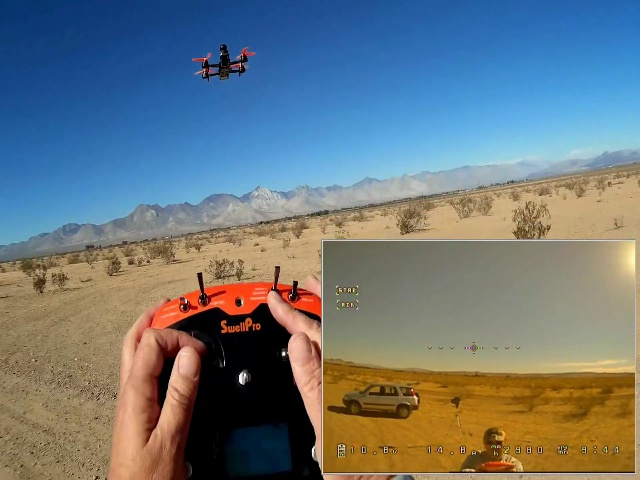

In [ ]:
from PIL import Image
from IPython.display import display
from datasets import load_dataset, Dataset, DatasetDict
from datasets import Image as DatasetImage

def load_subset(split, count, *, shuffle=True, seed=SEED):
    # 전체 4.65GB를 내려받지 않고 필요한 subset만 streaming으로 읽습니다.
    stream = load_dataset(
        dataset_id, split=split, revision=dataset_revision, streaming=True,
    ).cast_column("image", DatasetImage(decode=False))
    if shuffle:
        stream = stream.shuffle(seed=seed, buffer_size=1000)
    rows = list(stream.take(count))
    if len(rows) != count:
        raise ValueError(f"{split}: {count}장을 요청했으나 {len(rows)}장입니다.")
    for row in rows:
        objects = row["objects"]
        if len(objects["category"]) != len(objects["bbox"]):
            raise ValueError("정답 라벨과 박스 개수가 다릅니다.")
        if any(int(category) != 0 for category in objects["category"]):
            raise ValueError("drone(category=0) 외의 라벨이 있습니다.")
    return Dataset.from_list(rows, features=stream.features).cast_column(
        "image", DatasetImage(decode=True),
    )

# 첫 추론도 드론 이미지로 진행합니다. 5번에서 이 20장을 재사용합니다.
preview_ds = load_subset("train", 20, shuffle=False)
image = preview_ds[0]["image"].convert("RGB")
image

threshold 이상 예측: 38개 (상위 최대 10개 표시)
drone      0.612 box={'xmin': 0, 'ymin': 316, 'xmax': 6, 'ymax': 476}
drone      0.602 box={'xmin': 0, 'ymin': 447, 'xmax': 58, 'ymax': 480}
drone      0.570 box={'xmin': 39, 'ymin': 298, 'xmax': 57, 'ymax': 311}
drone      0.565 box={'xmin': 75, 'ymin': 297, 'xmax': 92, 'ymax': 310}
drone      0.565 box={'xmin': 12, 'ymin': 296, 'xmax': 29, 'ymax': 309}
drone      0.564 box={'xmin': 267, 'ymin': 471, 'xmax': 437, 'ymax': 480}
drone      0.563 box={'xmin': 11, 'ymin': 293, 'xmax': 31, 'ymax': 308}
drone      0.563 box={'xmin': 31, 'ymin': 294, 'xmax': 53, 'ymax': 309}
drone      0.562 box={'xmin': 33, 'ymin': 295, 'xmax': 49, 'ymax': 309}
drone      0.562 box={'xmin': 473, 'ymin': 457, 'xmax': 549, 'ymax': 480}


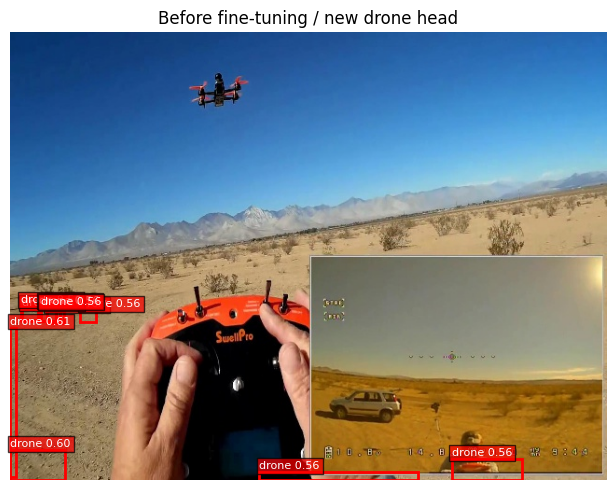

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def show_detections(image, detections, title="Predictions", ax=None):
    own_figure = ax is None
    if own_figure:
        _, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(image)
    # 새 1-class head의 학습 전에는 많은 중복 박스가 나올 수 있습니다.
    # 그림은 점수가 높은 10개만 표시하며, mAP에는 모든 예측을 사용합니다.
    shown = sorted(detections, key=lambda r: r.get("score", 1.0), reverse=True)
    if shown and "score" in shown[0]:
        shown = shown[:10]
    for result in shown:
        box = result["box"]
        x1, y1, x2, y2 = [box[key] for key in ("xmin", "ymin", "xmax", "ymax")]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="red", linewidth=2))
        text = result["label"]
        if "score" in result:
            text += f" {result['score']:.2f}"
        ax.text(x1, max(0, y1 - 3), text, fontsize=8, color="white",
                bbox={"facecolor": "red", "alpha": 0.7, "pad": 2})
    ax.set_title(title)
    ax.axis("off")
    if own_figure:
        plt.tight_layout()
        plt.show()

def print_detections(results):
    print(f"threshold 이상 예측: {len(results)}개 (상위 최대 10개 표시)")
    for result in sorted(results, key=lambda r: r["score"], reverse=True)[:10]:
        print(f"{result['label']:10s} {result['score']:.3f} box={result['box']}")

results = detector(image, threshold=threshold)
print_detections(results)
show_detections(image, results, title="Before fine-tuning / new drone head")

**결과 해석**
- `label`: drone
- `score`: 해당 박스가 drone이라는 예측 확신도
- `box`: 원본 이미지 픽셀 좌표 `[xmin, ymin, xmax, ymax]`

새 분류층을 아직 학습하지 않아 중복·오탐 박스가 많거나, 임계값 이상의 예측이 없을 수 있습니다.
그림은 상위 10개 박스만 보여 줍니다. 뒤의 mAP는 임계값 0.0으로 전체 query 예측을 평가합니다.

---
## 4. 내 이미지로 바꿔보기

직접 업로드한 이미지에도 **학습 전 모델**을 적용해 봅니다.
아래 업로드 창에서 취소하면 앞의 예제 이미지를 그대로 사용합니다.

In [ ]:
from google.colab import files
uploaded = files.upload()

threshold 이상 예측: 38개 (상위 최대 10개 표시)
drone      0.612 box={'xmin': 0, 'ymin': 316, 'xmax': 6, 'ymax': 476}
drone      0.602 box={'xmin': 0, 'ymin': 447, 'xmax': 58, 'ymax': 480}
drone      0.570 box={'xmin': 39, 'ymin': 298, 'xmax': 57, 'ymax': 311}
drone      0.565 box={'xmin': 75, 'ymin': 297, 'xmax': 92, 'ymax': 310}
drone      0.565 box={'xmin': 12, 'ymin': 296, 'xmax': 29, 'ymax': 309}
drone      0.564 box={'xmin': 267, 'ymin': 471, 'xmax': 437, 'ymax': 480}
drone      0.563 box={'xmin': 11, 'ymin': 293, 'xmax': 31, 'ymax': 308}
drone      0.563 box={'xmin': 31, 'ymin': 294, 'xmax': 53, 'ymax': 309}
drone      0.562 box={'xmin': 33, 'ymin': 295, 'xmax': 49, 'ymax': 309}
drone      0.562 box={'xmin': 473, 'ymin': 457, 'xmax': 549, 'ymax': 480}


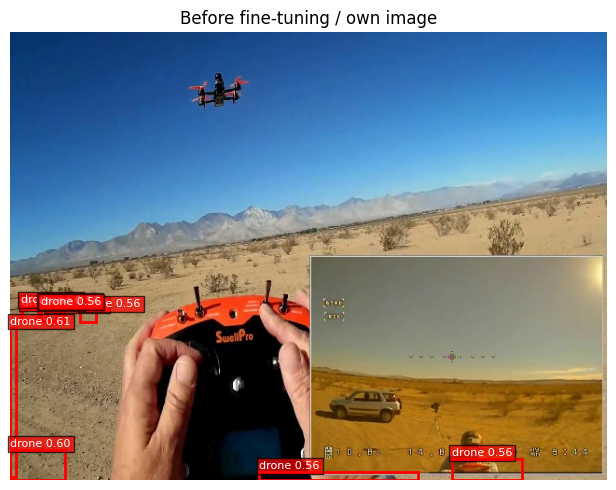

In [ ]:
# 업로드는 선택 사항입니다. 취소해도 전체 실습을 계속할 수 있습니다.
if uploaded:
    my_image = Image.open(next(iter(uploaded))).convert("RGB")
else:
    my_image = image
results = detector(my_image, threshold=threshold)
print_detections(results)
show_detections(my_image, results, title="Before fine-tuning / own image")

---
## 5. 공개 데이터셋 불러오기 (`datasets`)

`pathikg/drone-detection-dataset`은 train / test split과 **실제 드론 박스 주석**을 제공합니다.
라벨은 `objects.category=0` 하나이며 이름은 drone입니다.
저장된 `objects.bbox`는 **COCO XYWH** `[x, y, width, height]` 형식입니다.
DETR processor에도 XYWH로 전달하고, 그림과 mAP 계산에서는 XYXY 형식으로 변환합니다.

전체 데이터 대신 Colab 실습용 subset을 streaming으로 읽습니다.

In [ ]:
# 첫 번째 추론 때 읽은 20장 재사용
ds = preview_ds
print(ds)
print("라벨:", id2label)
print("첫 이미지의 정답:", ds[0]["objects"])

Dataset({
    features: ['width', 'height', 'objects', 'image', 'image_id'],
    num_rows: 20
})
라벨: {0: 'drone'}
첫 이미지의 정답: {'bbox': [[193.0, 43.0, 63.0, 41.0]], 'category': [0], 'area': [2583.0], 'id': [0]}


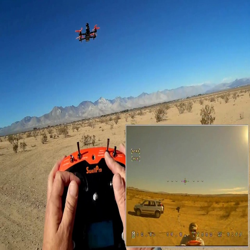

정답 라벨: ['drone']


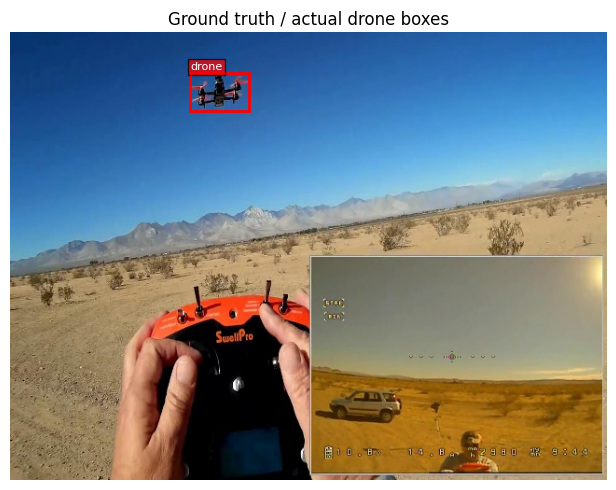

In [ ]:
def ground_truth(sample):
    results = []
    for category, box in zip(sample["objects"]["category"], sample["objects"]["bbox"]):
        x, y, width, height = map(float, box)  # 데이터는 XYWH
        results.append({
            "label": labels[int(category)],
            "box": {"xmin": x, "ymin": y, "xmax": x + width, "ymax": y + height},
        })
    return results

sample = ds[0]
display(sample["image"].resize((250, 250)))
print("정답 라벨:", [result["label"] for result in ground_truth(sample)])
show_detections(sample["image"], ground_truth(sample), title="Ground truth / actual drone boxes")

### 실습 (직접 해보기)
아래 셀에서 **학습 전 모델 예측 vs 실제 드론 정답**을 비교하세요.
이 단계까지 학습은 하지 않았습니다.
같은 drone 라벨이 나왔더라도 위치가 틀리거나 중복 박스가 많으면 검출에 성공한 것으로 볼 수 없습니다.

In [ ]:
# 데이터셋 이미지 3장에 대해 예측해보기
for i in range(3):
    sample = ds[i]
    img = sample["image"].convert("RGB")
    true_labels = [r["label"] for r in ground_truth(sample)]
    predictions = detector(img, threshold=threshold)
    print(f"[{i}] 실제: {true_labels}")
    print_detections(predictions)

[0] 실제: ['drone']
threshold 이상 예측: 38개 (상위 최대 10개 표시)
drone      0.612 box={'xmin': 0, 'ymin': 316, 'xmax': 6, 'ymax': 476}
drone      0.602 box={'xmin': 0, 'ymin': 447, 'xmax': 58, 'ymax': 480}
drone      0.570 box={'xmin': 39, 'ymin': 298, 'xmax': 57, 'ymax': 311}
drone      0.565 box={'xmin': 75, 'ymin': 297, 'xmax': 92, 'ymax': 310}
drone      0.565 box={'xmin': 12, 'ymin': 296, 'xmax': 29, 'ymax': 309}
drone      0.564 box={'xmin': 267, 'ymin': 471, 'xmax': 437, 'ymax': 480}
drone      0.563 box={'xmin': 11, 'ymin': 293, 'xmax': 31, 'ymax': 308}
drone      0.563 box={'xmin': 31, 'ymin': 294, 'xmax': 53, 'ymax': 309}
drone      0.562 box={'xmin': 33, 'ymin': 295, 'xmax': 49, 'ymax': 309}
drone      0.562 box={'xmin': 473, 'ymin': 457, 'xmax': 549, 'ymax': 480}
[1] 실제: ['drone']
threshold 이상 예측: 73개 (상위 최대 10개 표시)
drone      0.619 box={'xmin': 0, 'ymin': 190, 'xmax': 2, 'ymax': 243}
drone      0.600 box={'xmin': 0, 'ymin': 201, 'xmax': 17, 'ymax': 216}
drone      0.594 box={'xmin': 

---
## 6-1. 전이학습(Transfer Learning)의 개념

```
사전학습 DETR (ResNet-50 + Transformer + 박스 head 재사용)
        ↓ 분류층만 drone용으로 교체
drone + no-object의 새 분류층 (2개 출력)
        ↓ 학습 없이 예측·평가: Before
동일한 초기 모델을 train 데이터로 파인튜닝
        ↓ 동일한 test 이미지로 평가: After
```

`num_labels=1`, `ignore_mismatched_sizes=True`로 실제 분류층 출력을 **92 → 2**로 교체합니다.
기존 COCO 분류층의 라벨 이름만 drone으로 바꾸는 방식은 사용하지 않습니다.
새 분류층은 3번에서 한 번만 생성하며, 첫 추론부터 파인튜닝까지 같은 모델을 재사용합니다.
기존처럼 파라미터를 추가로 동결하는 설정은 넣지 않습니다.

In [ ]:
# 첫 추론에 쓴 모델의 구조를 확인합니다. 여기서 다시 초기화하지 않습니다.
model = detector.model
print("교체 전 분류층 출력:", original_num_labels + 1)
print("교체 후 분류층 출력:", model.class_labels_classifier.out_features)
print("새 객체 클래스 수:", model.config.num_labels)
print("라벨 매핑:", model.config.id2label)
assert model.class_labels_classifier.out_features == len(labels) + 1

교체 전 분류층 출력: 92
교체 후 분류층 출력: 2
새 객체 클래스 수: 1
라벨 매핑: {0: 'drone'}


학습 전후의 출발점이 같도록 모델을 다시 불러오거나 분류층을 재초기화하지 않습니다.
특징 추출기·Transformer·박스 head는 사전학습 가중치에서,
drone 분류층은 무작위 초기화 상태에서 시작합니다.
Before의 결과는 새 분류층을 붙인 모델의 학습 전 성능입니다.

---
## 6-2. 전이학습 실습 — `Trainer`로 파인튜닝하기

drone용 새 분류층을 붙인 모델을 실제 드론 박스 주석으로 파인튜닝합니다.
`Trainer`가 순전파·역전파·평가·저장을 처리합니다.

**기존 설정 유지**: 학습 500장 / 검증 100장 / 평가 100장,
batch size 16, 3 epoch, learning rate 5e-5, 이미지 해상도 224/384.
검증 loss가 가장 낮은 checkpoint를 최종 모델로 선택합니다.

In [ ]:
# 학습에 필요한 라이브러리 추가 설치
%pip install -q "transformers==4.57.6" "datasets==4.4.1" "accelerate>=1.0,<2" "torchmetrics==1.8.2" "pycocotools>=2.0,<3"
print("설치 완료")

설치 완료


### ① 데이터셋과 전처리기 준비

train split에서 600장을 고정 seed로 추출해 학습 500장·검증 100장으로 나눕니다.
최종 평가 100장은 별도의 test split에서 가져옵니다.
`with_transform`으로 배치를 불러올 때 전처리합니다.

작은 드론이 많아 실습 해상도 224/384에서는 검출이 어려울 수 있습니다.
이번 비교는 학습 전후에 동일한 해상도와 평가 이미지를 사용합니다.
원본 영상 그룹 ID가 제공되지 않으므로 영상 단위의 완전한 독립 검증을 보장하는 분할은 아닙니다.

In [ ]:
import math

NUM_TRAIN, NUM_VAL, NUM_TEST = 512, 128, 128
train_pool = load_subset("train", NUM_TRAIN + NUM_VAL, seed=SEED)
split = train_pool.train_test_split(test_size=NUM_VAL, seed=SEED)
raw_ds = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": load_subset("test", NUM_TEST, seed=SEED + 1),
})
assert set(raw_ds["train"]["image_id"]).isdisjoint(raw_ds["validation"]["image_id"])
print(raw_ds)

def coco_target(image_id, objects, image_size):
    width, height = image_size
    annotations = []
    for category, box in zip(objects["category"], objects["bbox"]):
        x, y, box_width, box_height = map(float, box)  # 원본 주석은 XYWH
        if not all(math.isfinite(v) for v in (x, y, box_width, box_height)):
            continue
        if box_width <= 0 or box_height <= 0:
            continue
        x1, y1 = min(max(x, 0.0), width), min(max(y, 0.0), height)
        x2 = min(max(x + box_width, 0.0), width)
        y2 = min(max(y + box_height, 0.0), height)
        if x2 <= x1 or y2 <= y1:
            continue
        category = int(category)
        if category != 0:
            raise ValueError(f"drone(0) 외의 클래스: {category}")
        annotations.append({
            "category_id": category,
            "bbox": [x1, y1, x2 - x1, y2 - y1],
            "area": (x2 - x1) * (y2 - y1), "iscrowd": 0,
        })
    return {"image_id": int(image_id), "annotations": annotations}

def transform(batch):
    inputs = {"pixel_values": [], "labels": []}
    for img, image_id, objects in zip(batch["image"], batch["image_id"], batch["objects"]):
        img = img.convert("RGB")
        encoded = processor(
            images=img, annotations=coco_target(image_id, objects, img.size),
            return_tensors="pt",
        )
        inputs["pixel_values"].append(encoded["pixel_values"][0])
        inputs["labels"].append(encoded["labels"][0])
    return inputs

ds = raw_ds.with_transform(transform)
print("데이터 준비 완료 / 같은 test를 학습 전후에 사용합니다.")

DatasetDict({
    train: Dataset({
        features: ['width', 'height', 'objects', 'image', 'image_id'],
        num_rows: 512
    })
    validation: Dataset({
        features: ['width', 'height', 'objects', 'image', 'image_id'],
        num_rows: 128
    })
    test: Dataset({
        features: ['width', 'height', 'objects', 'image', 'image_id'],
        num_rows: 128
    })
})
데이터 준비 완료 / 같은 test를 학습 전후에 사용합니다.


### ② 배치 묶기(collator)와 평가지표

이미지 padding과 `pixel_mask`를 만들고, 정답 객체는 dictionary의 list로 유지합니다.
클래스와 박스를 함께 평가하는 mAP, mAP@0.50, mAP@0.75, mAR@100을 사용합니다.
시각화는 임계값 0.5와 상위 10개 박스를 사용하고,
**mAP에는 임계값 0.0으로 전체 query 예측**을 전달합니다.

In [ ]:
import numpy as np
from types import SimpleNamespace
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# 직접 정의한 collator로 배치를 묶기
def collate_fn(batch):
    padded = processor.pad([x["pixel_values"] for x in batch], return_tensors="pt")
    return {
        "pixel_values": padded["pixel_values"],
        "pixel_mask": padded["pixel_mask"],
        "labels": [x["labels"] for x in batch],
    }

# compute_metrics 인터페이스 유지, 정확도 → 객체검출 mAP
@torch.no_grad()
def compute_metrics(eval_pred):
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    for (logits, pred_boxes), batch_targets in zip(eval_pred.predictions, eval_pred.label_ids):
        sizes = torch.tensor(np.stack([target["orig_size"] for target in batch_targets]))
        outputs = SimpleNamespace(
            logits=torch.as_tensor(logits), pred_boxes=torch.as_tensor(pred_boxes),
        )
        predictions = processor.post_process_object_detection(
            outputs, target_sizes=sizes, threshold=0.0,
        )
        references = []
        for target, (height, width) in zip(batch_targets, sizes.tolist()):
            boxes = torch.as_tensor(target["boxes"], dtype=torch.float32).reshape(-1, 4)
            centers, spans = boxes[:, :2], boxes[:, 2:]
            corners = torch.cat([centers - spans / 2, centers + spans / 2], dim=1)
            corners *= torch.tensor([width, height, width, height])
            references.append({
                "boxes": corners,
                "labels": torch.as_tensor(target["class_labels"], dtype=torch.int64),
            })
        metric.update(predictions, references)
    result = metric.compute()
    return {key: float(result[key].item()) for key in ("map", "map_50", "map_75", "mar_100")}

print("collator·지표 준비 완료")

from transformers import Trainer

class ObjectDetectionTrainer(Trainer):
    def evaluation_loop(self, *args, **kwargs):
        if self.accelerator.num_processes == 1:
            self.gather_function = self.accelerator.gather
        return super().evaluation_loop(*args, **kwargs)

collator·지표 준비 완료


### ③ 사전학습 모델 준비 (교체한 분류층 유지)

첫 추론에서 만든 **drone용 모델**을 Trainer에 연결합니다.
여기서 모델을 다시 불러오지 않아 학습 전 평가와 파인튜닝의 초기 가중치를 일치시킵니다.

In [ ]:
model = detector.model  # 첫 예측과 같은 가중치에서 출발
assert model.config.num_labels == 1
assert model.config.id2label == id2label

# compute_metrics에는 (logits, pred_boxes)만 전달합니다.
model.config.keys_to_ignore_at_inference = [
    "loss_dict", "auxiliary_outputs", "last_hidden_state",
    "decoder_hidden_states", "decoder_attentions", "cross_attentions",
    "encoder_last_hidden_state", "encoder_hidden_states", "encoder_attentions",
]
print("학습 전 모델 유지 완료 / 분류층 출력:", model.class_labels_classifier.out_features)

학습 전 모델 유지 완료 / 분류층 출력: 2


### ④ 학습 설정 & 실행

먼저 **학습 전 test 성능과 예측을 기록**하고, 그다음 `train()`을 한 번 실행합니다.
학습·checkpoint 선택에는 train·validation만 사용하고 test는 비교용으로만 사용합니다.
기존의 epoch별 평가·저장, 검증 loss 기준 best checkpoint 선택을 유지합니다.
객체검출용 `remove_unused_columns=False`, `eval_do_concat_batches=False`도 유지합니다.

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./detr-drone",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=16,
    load_best_model_at_end=True,
    remove_unused_columns=False,
    eval_do_concat_batches=False,
    label_names=["labels"],
    report_to="none",
    seed=SEED,
)
trainer = ObjectDetectionTrainer(
    model=model, args=training_args,
    train_dataset=ds["train"], eval_dataset=ds["validation"],
    processing_class=processor, data_collator=collate_fn, compute_metrics=compute_metrics,
)

# train() 전에 평가: 분류층을 붙였지만 한 번도 학습하지 않은 상태
before_metrics = trainer.evaluate(ds["test"], metric_key_prefix="before")
before_predictions = [
    detector(raw_ds["test"][i]["image"].convert("RGB"), threshold=threshold)
    for i in range(min(3, NUM_TEST))
]
print("학습 전 mAP:", round(before_metrics["before_map"], 4))

trainer.train()

학습 전 mAP: 0.0005


Epoch,Training Loss,Validation Loss,Model Preparation Time,Map,Map 50,Map 75,Mar 100
1,1.427000,1.234689,0.021300,0.004736,0.011500,0.002951,0.500781
2,1.286800,1.056534,0.021300,0.010581,0.023832,0.007267,0.549219
3,1.207000,0.995089,0.021300,0.013987,0.029913,0.010111,0.575781


TrainOutput(global_step=96, training_loss=1.3893437186876934, metrics={'train_runtime': 107.9724, 'train_samples_per_second': 14.226, 'train_steps_per_second': 0.889, 'total_flos': 7.654648749214925e+16, 'train_loss': 1.3893437186876934, 'epoch': 3.0})

### ⑤ 최종 성능 확인 & 파인튜닝 모델로 추론

같은 test 이미지·라벨·해상도·평가 코드로 학습 후 성능을 측정합니다.
Before는 사전학습 DETR + 학습하지 않은 drone 분류층,
After는 그 모델을 파인튜닝해 검증 loss로 선택한 checkpoint입니다.
실제 실행 결과로 점수와 증감을 계산하며 성능 향상을 미리 가정하지 않습니다.

In [ ]:
import pandas as pd

after_metrics = trainer.evaluate(ds["test"], metric_key_prefix="after")
metric_names = {"mAP": "map", "mAP@0.50": "map_50", "mAP@0.75": "map_75", "mAR@100": "mar_100"}
comparison = pd.DataFrame({
    "Before (new head, no fine-tuning)":
        {name: before_metrics[f"before_{key}"] for name, key in metric_names.items()},
    "After (fine-tuned)":
        {name: after_metrics[f"after_{key}"] for name, key in metric_names.items()},
}).T
comparison.loc["After - Before"] = comparison.iloc[1] - comparison.iloc[0]
display(comparison.round(4))
print("평가 이미지:", NUM_TEST, "장 / 실제 드론 박스 주석 사용")

,mAP,mAP@0.50,mAP@0.75,mAR@100
"Before (new head, no fine-tuning)",0.0005,0.0015,0.0002,0.1681
After (fine-tuned),0.0086,0.0269,0.0042,0.4203
After - Before,0.0081,0.0255,0.0040,0.2522


평가 이미지: 128 장 / 실제 드론 박스 주석 사용


Device set to use cuda:0


[0] 정답 드론 수: 1
Before:
threshold 이상 예측: 21개 (상위 최대 10개 표시)
drone      0.611 box={'xmin': 0, 'ymin': 388, 'xmax': 18, 'ymax': 479}
drone      0.542 box={'xmin': 31, 'ymin': 369, 'xmax': 346, 'ymax': 480}
drone      0.542 box={'xmin': 0, 'ymin': 11, 'xmax': 98, 'ymax': 50}
drone      0.535 box={'xmin': 50, 'ymin': 31, 'xmax': 90, 'ymax': 61}
drone      0.534 box={'xmin': 2, 'ymin': 19, 'xmax': 101, 'ymax': 68}
drone      0.534 box={'xmin': 412, 'ymin': 395, 'xmax': 477, 'ymax': 479}
drone      0.526 box={'xmin': 84, 'ymin': 10, 'xmax': 165, 'ymax': 37}
drone      0.526 box={'xmin': 0, 'ymin': 21, 'xmax': 98, 'ymax': 95}
drone      0.526 box={'xmin': 616, 'ymin': 178, 'xmax': 640, 'ymax': 322}
drone      0.526 box={'xmin': 0, 'ymin': 12, 'xmax': 6, 'ymax': 104}
After:
threshold 이상 예측: 0개 (상위 최대 10개 표시)


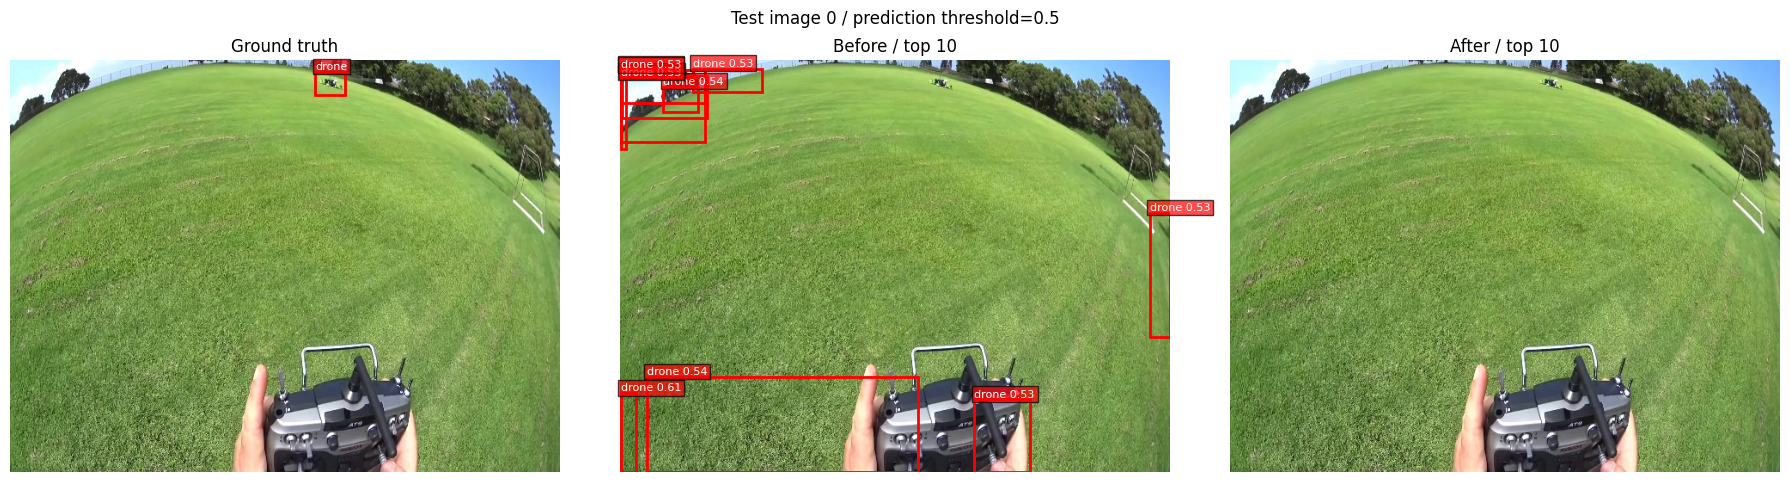

[1] 정답 드론 수: 1
Before:
threshold 이상 예측: 63개 (상위 최대 10개 표시)
drone      0.613 box={'xmin': 0, 'ymin': 246, 'xmax': 12, 'ymax': 319}
drone      0.613 box={'xmin': 0, 'ymin': 192, 'xmax': 14, 'ymax': 324}
drone      0.594 box={'xmin': 0, 'ymin': 228, 'xmax': 9, 'ymax': 336}
drone      0.593 box={'xmin': 0, 'ymin': 100, 'xmax': 15, 'ymax': 357}
drone      0.591 box={'xmin': 0, 'ymin': 229, 'xmax': 5, 'ymax': 312}
drone      0.591 box={'xmin': 0, 'ymin': 208, 'xmax': 9, 'ymax': 292}
drone      0.589 box={'xmin': 0, 'ymin': 432, 'xmax': 243, 'ymax': 479}
drone      0.588 box={'xmin': 0, 'ymin': 164, 'xmax': 4, 'ymax': 342}
drone      0.588 box={'xmin': 0, 'ymin': 343, 'xmax': 5, 'ymax': 471}
drone      0.581 box={'xmin': 0, 'ymin': 98, 'xmax': 8, 'ymax': 319}
After:
threshold 이상 예측: 0개 (상위 최대 10개 표시)


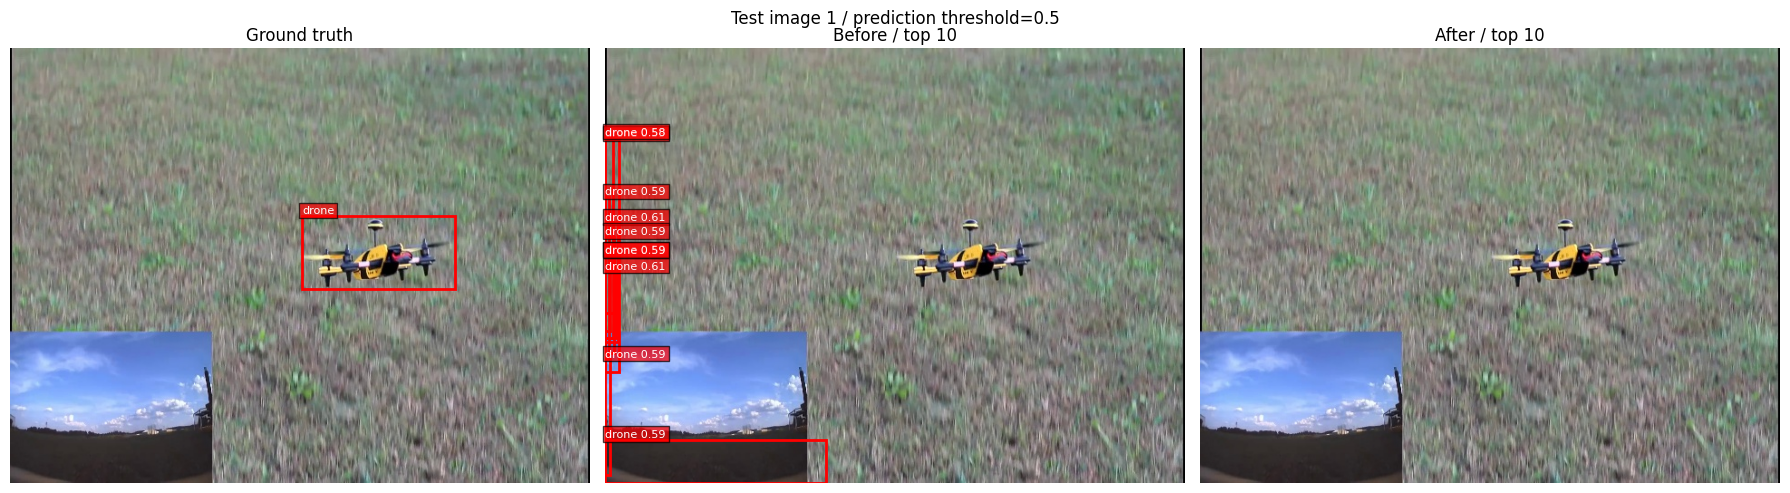

[2] 정답 드론 수: 1
Before:
threshold 이상 예측: 62개 (상위 최대 10개 표시)
drone      0.583 box={'xmin': 0, 'ymin': 77, 'xmax': 31, 'ymax': 152}
drone      0.583 box={'xmin': 0, 'ymin': 419, 'xmax': 62, 'ymax': 480}
drone      0.566 box={'xmin': 0, 'ymin': 2, 'xmax': 60, 'ymax': 479}
drone      0.566 box={'xmin': 0, 'ymin': 0, 'xmax': 59, 'ymax': 480}
drone      0.566 box={'xmin': 8, 'ymin': 415, 'xmax': 418, 'ymax': 480}
drone      0.563 box={'xmin': 0, 'ymin': 370, 'xmax': 46, 'ymax': 480}
drone      0.562 box={'xmin': 8, 'ymin': 434, 'xmax': 463, 'ymax': 479}
drone      0.561 box={'xmin': 0, 'ymin': 433, 'xmax': 394, 'ymax': 480}
drone      0.555 box={'xmin': 0, 'ymin': 178, 'xmax': 107, 'ymax': 478}
drone      0.553 box={'xmin': 0, 'ymin': 247, 'xmax': 137, 'ymax': 477}
After:
threshold 이상 예측: 0개 (상위 최대 10개 표시)


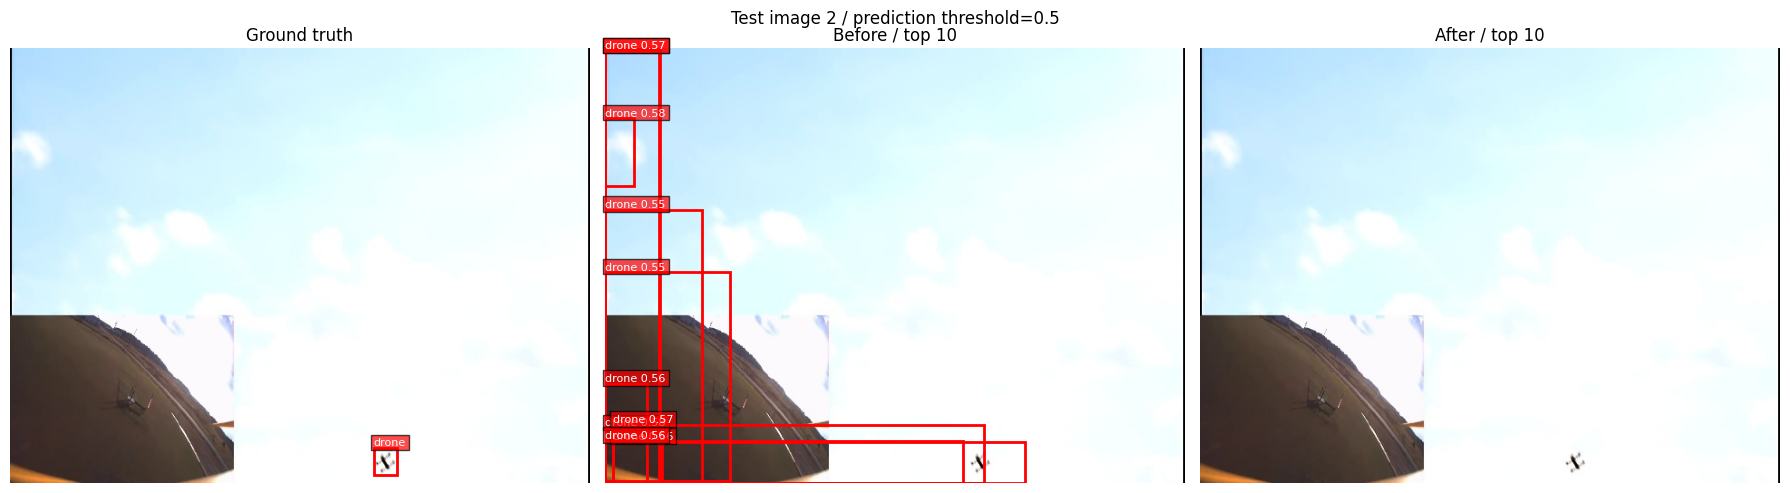

In [ ]:
detector_finetuned = pipeline(
    "object-detection", model=trainer.model, image_processor=processor, device=device,
)

# 학습 전에 저장한 예측과 같은 이미지의 학습 후 예측을 나란히 표시
for i, before in enumerate(before_predictions):
    sample = raw_ds["test"][i]
    img = sample["image"].convert("RGB")
    after = detector_finetuned(img, threshold=threshold)
    print(f"[{i}] 정답 드론 수:", len(sample["objects"]["category"]))
    print("Before:")
    print_detections(before)
    print("After:")
    print_detections(after)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    show_detections(img, ground_truth(sample), title="Ground truth", ax=axes[0])
    show_detections(img, before, title="Before / top 10", ax=axes[1])
    show_detections(img, after, title="After / top 10", ax=axes[2])
    fig.suptitle(f"Test image {i} / prediction threshold={threshold}")
    plt.tight_layout()
    plt.show()

### ⑥ 학습 곡선 그리기

`Trainer`는 학습 과정의 기록을 `trainer.state.log_history`에 남깁니다.
여기서 **학습 loss**, **검증 loss**, **검증 mAP**를 꺼내 그래프로 그려봅니다.
곡선을 보면 학습이 잘 되고 있는지(수렴), 과적합이 시작되는지 등을 판단할 수 있습니다.

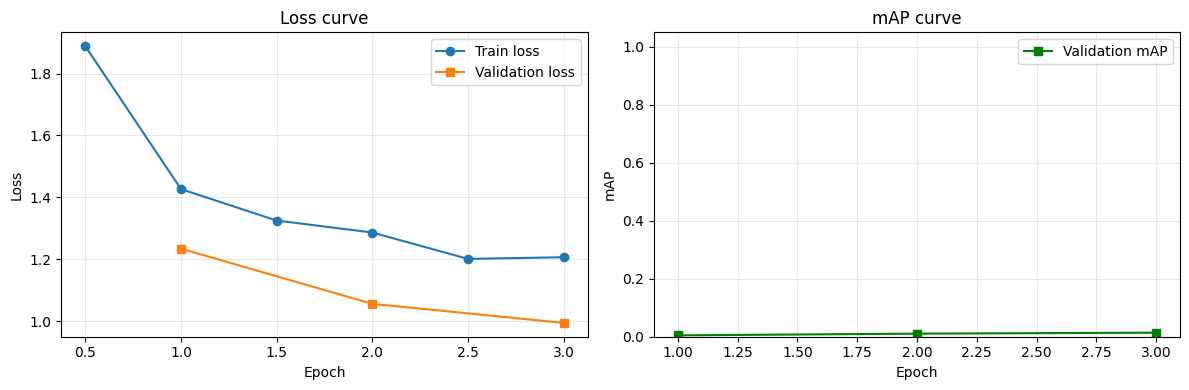

In [ ]:
import matplotlib.pyplot as plt

# Trainer가 남긴 로그에서 필요한 값 추출
logs = trainer.state.log_history

train_steps, train_loss = [], []      # 학습 loss (logging_steps 마다 기록)
eval_epochs, eval_loss, eval_map = [], [], []   # 검증 지표 (epoch 마다 기록)

for rec in logs:
    if "loss" in rec and "epoch" in rec and "eval_loss" not in rec:
        train_steps.append(rec["epoch"])
        train_loss.append(rec["loss"])
    if "eval_loss" in rec:
        eval_epochs.append(rec["epoch"])
        eval_loss.append(rec["eval_loss"])
        eval_map.append(rec["eval_map"])

# 그래프 2개: (왼쪽) loss, (오른쪽) mAP
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 왼쪽 — Loss 곡선
ax1.plot(train_steps, train_loss, marker="o", label="Train loss")
ax1.plot(eval_epochs, eval_loss, marker="s", label="Validation loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Loss curve")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 오른쪽 — mAP 곡선
ax2.plot(eval_epochs, eval_map, marker="s", color="green", label="Validation mAP")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("mAP")
ax2.set_title("mAP curve")
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**곡선 해석 팁**
- 학습 loss·검증 loss·검증 mAP를 함께 살펴봅니다.
- 학습 loss만 내려가고 검증 loss가 올라가면 과적합 가능성이 있습니다.
- 3 epoch와 작은 평가셋만으로 수렴 또는 성능 향상을 단정하지 않습니다.

작은 객체는 박스가 조금만 어긋나도 IoU가 크게 바뀔 수 있습니다.
이번 비교에서는 학습 전후의 평가 이미지와 해상도를 고정해 그 영향을 같게 합니다.

**정리**
- 사전학습 DETR에 drone용 새 분류층을 붙여 학습 전후를 비교했습니다.
- 특징 추출기·Transformer·박스 head의 사전학습 가중치를 재사용합니다.
- 실제 드론 박스 주석으로 mAP를 계산하고, 같은 이미지의 정답·학습 전·학습 후 박스를 비교합니다.

---
## 7. 정리

| 단계 | 이번 실습 |
|---|---|
| ① 모델 찾기 | `facebook/detr-resnet-50` |
| ② 불러오기 | drone용 새 분류층 + `pipeline` |
| ③ 데이터 적용 | `pathikg/drone-detection-dataset` |
| ④ 추론 | 파인튜닝 없이 예측 |
| ⑤ 전이학습 | 학습 전 평가 → 동일 모델 파인튜닝 → 같은 test로 평가 |

**유지한 설정**: 41개 셀 순서, 학습 500장 / 검증 100장 / 평가 100장,
batch size 16, 3 epoch, learning rate 5e-5, epoch별 평가·저장,
검증 loss 기준 best checkpoint 선택, 해상도 224/384.

**데이터·라벨**: `category=0`은 drone이며 실제 박스는 XYWH입니다.
학습·검증은 train split을 나누고, 최종 평가는 test split에서 추출합니다.
분류층 출력은 no-object를 포함해 **92 → 2**로 교체합니다.
교체한 분류층을 재초기화하지 않고 같은 모델을 파인튜닝합니다.
영상 프레임 데이터의 특성과 작은 객체·적은 표본·실습 해상도를 고려해 결과를 해석하세요.

[데이터셋·박스 형식](https://huggingface.co/datasets/pathikg/drone-detection-dataset) ·
[모델 카드](https://huggingface.co/facebook/detr-resnet-50) ·
[Transformers 객체검출 가이드](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/object_detection)

전체 Colab GPU 3 epoch 학습은 실행하지 않았습니다. 성능 표는 노트북 실행 후 채워집니다.